# Week 11 - Clustering 2, DBSCAN and Hierarchical Clustering
## Dataset: FEMA NFIP Claims

This week covers two more clustering methods, DBSCAN and hierarchical agglomerative clustering (HAC). Both avoid the main limits of k-means from Week 10, which needs the number of clusters in advance, assigns every point to some cluster, and favors round clusters of similar size.

DBSCAN (density-based spatial clustering of applications with noise) grows clusters wherever points are densely packed and labels points in sparse areas as noise. A point is a core point if at least `min_samples` points, counting itself, lie within a distance `eps` of it. Clusters are chains of core points within `eps` of each other, plus the points they reach, and everything else is noise. The number of clusters comes out of the data, and clusters can take any shape.

HAC starts with every point as its own cluster and repeatedly merges the two closest clusters until one remains. The linkage method defines the distance between two clusters, the closest pair of points (single linkage), the farthest pair (complete), the average over all pairs (average), or the increase in within-cluster variance caused by the merge (Ward). The merge history is drawn as a dendrogram, a tree whose branch heights show how far apart the merged clusters were, and cutting the tree at a height gives the clusters.

The notebook applies DBSCAN to claim locations, to find the flood disasters of 2017 and separate them from scattered claims, and HAC to county profiles, to see which flood-affected counties resemble each other.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings('ignore', category=FutureWarning)

columns = ['yearOfLoss', 'amountPaidOnBuildingClaim', 'originalConstructionDate', 'ratedFloodZone',
           'buildingReplacementCost', 'totalBuildingInsuranceCoverage', 'waterDepth',
           'numberOfFloorsInTheInsuredBuilding', 'elevatedBuildingIndicator', 'primaryResidenceIndicator',
           'postFIRMConstructionIndicator', 'latitude', 'longitude', 'floodEvent', 'state', 'countyCode']
df_raw = pd.read_csv('FimaNfipClaimsV2.csv', low_memory=False, usecols=columns)
df = df_raw[(df_raw['yearOfLoss'] == 2017) & (df_raw['amountPaidOnBuildingClaim'] >= 0)].copy()
print('2017 claims with a non-negative building payout:', len(df))

2017 claims with a non-negative building payout: 113398


### Data

The claims are the same 101,042 used since Week 4. The redacted coordinates are rounded to 0.1 degree, so the claims sit at 3,580 distinct locations. DBSCAN runs on those locations with each weighted by its number of claims, so `min_samples` counts claims, not locations.

In [2]:
df['constructionYear'] = pd.to_datetime(df['originalConstructionDate'], errors='coerce').dt.year
zone_letter = df['ratedFloodZone'].astype(str).str.upper().str[0]
df['zoneA'] = (zone_letter == 'A').astype(int)
df['zoneV'] = (zone_letter == 'V').astype(int)
df['logReplacementCost'] = np.log10(df['buildingReplacementCost'].clip(lower=1))
profile_features = ['waterDepth', 'logReplacementCost', 'numberOfFloorsInTheInsuredBuilding', 'elevatedBuildingIndicator',
                    'primaryResidenceIndicator', 'postFIRMConstructionIndicator', 'constructionYear', 'zoneA', 'zoneV']
data = df.dropna(subset=profile_features + ['latitude', 'longitude']).copy()
data = data[data['constructionYear'].between(1800, 2017)].reset_index(drop=True)
data['largeClaim'] = (data['amountPaidOnBuildingClaim'] > 50000).astype(int)
data['event'] = data['floodEvent'].fillna('Not named')

cells = data.groupby(['latitude', 'longitude']).size().rename('claims').reset_index()
claim_cell = data.merge(cells.reset_index()[['latitude', 'longitude', 'index']], on=['latitude', 'longitude'],
                        how='left')['index'].values
cell_rad = np.radians(cells[['latitude', 'longitude']].values)
print('Claims used:', len(data), '| distinct 0.1-degree locations:', len(cells))

Claims used: 101042 | distinct 0.1-degree locations: 3580


## Part A - DBSCAN on claim locations

### Choosing eps

DBSCAN uses the haversine distance, the great-circle distance on the Earth's surface, so `eps` can be set in kilometers. The usual way to choose `eps` is a sorted k-distance plot, which shows how far each point has to reach to find `min_samples` neighbors. The next cell computes, for every location, the distance at which it gathers 100 claims, and plots those distances in order.

Locations holding 100 or more claims by themselves: 155 of 3580, with 0.790 of all claims
Locations that never gather 100 claims within their 60 nearest locations: 66
Distance (km) at which a location gathers 100 claims, percentiles over the other locations:
10%     14.7
25%     29.5
50%     61.2
75%    129.0
90%    189.1


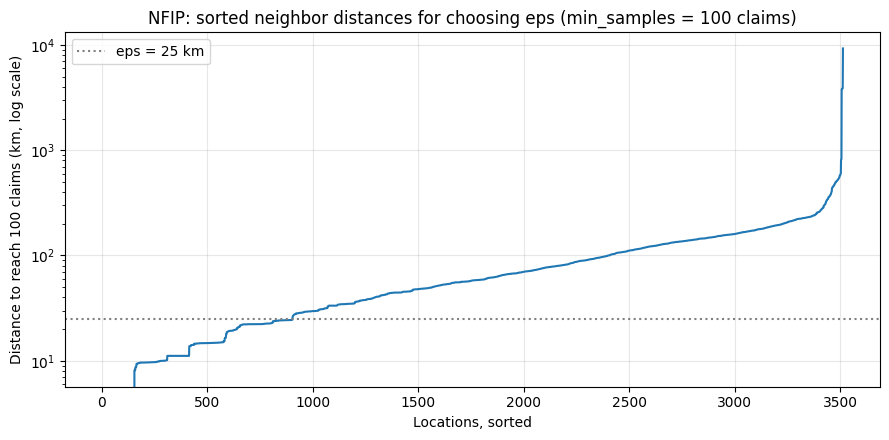

In [3]:
EARTH_KM = 6371.0
min_samples = 100
# Distance from each location to the point where its neighborhood holds min_samples claims (claims at a location count once each)
nn = NearestNeighbors(metric='haversine', algorithm='ball_tree').fit(cell_rad)
dist, idx = nn.kneighbors(cell_rad, n_neighbors=60)
cum = np.cumsum(cells['claims'].values[idx], axis=1)
reach = np.where(cum >= min_samples, dist, np.inf).min(axis=1) * EARTH_KM
own = cells['claims'] >= min_samples
print(f'Locations holding {min_samples} or more claims by themselves: {own.sum()} of {len(cells)}, '
      f'with {cells.loc[own, "claims"].sum() / len(data):.3f} of all claims')
print(f'Locations that never gather {min_samples} claims within their 60 nearest locations: {np.isinf(reach).sum()}')
print('Distance (km) at which a location gathers 100 claims, percentiles over the other locations:')
print(pd.Series(np.percentile(reach[np.isfinite(reach) & ~own.values], [10, 25, 50, 75, 90]),
                index=['10%', '25%', '50%', '75%', '90%']).round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(np.sort(reach[np.isfinite(reach)]))
ax.set_yscale('log')
ax.axhline(25, color='gray', linestyle=':', label='eps = 25 km')
ax.set_xlabel('Locations, sorted')
ax.set_ylabel('Distance to reach 100 claims (km, log scale)')
ax.set_title('NFIP: sorted neighbor distances for choosing eps (min_samples = 100 claims)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Most claims need no reach at all. 155 locations hold 100 or more claims by themselves, and together they hold 79% of all claims, which shows how concentrated the 2017 losses were. For the other locations, the median distance to gather 100 claims is 61 km, and the curve rises steadily with no single sharp knee, from 15 km at the 10th percentile to 189 km at the 90th. An `eps` around 25 km sits in the lower part of that curve, small enough that separate floods stay apart and large enough to bridge the 11 km grid of rounded coordinates. Since no single knee stands out, the next cell tries a grid of `eps` and `min_samples` values and compares each result with FEMA's flood event names using the adjusted Rand index (ARI), where 0 is what chance would give and 1 is perfect agreement.

In [4]:
grid_rows, results = [], {}
for eps_km in [12, 16, 25, 40, 60]:
    for ms in [20, 100, 500]:
        lab = DBSCAN(eps=eps_km / EARTH_KM, min_samples=ms, metric='haversine',
                     algorithm='ball_tree').fit(cell_rad, sample_weight=cells['claims']).labels_
        claim_lab = lab[claim_cell]
        results[(eps_km, ms)] = lab
        sizes = pd.Series(claim_lab[claim_lab >= 0]).value_counts()
        grid_rows.append({'eps (km)': eps_km, 'min_samples (claims)': ms, 'Clusters': int(lab.max() + 1),
                          'Noise share of claims': (claim_lab == -1).mean(), 'Noise share of locations': (lab == -1).mean(),
                          'Largest cluster share': sizes.iloc[0] / len(data),
                          'ARI with flood event': adjusted_rand_score(data['event'], claim_lab)})
grid = pd.DataFrame(grid_rows)
print(grid.round(3).to_string(index=False))

 eps (km)  min_samples (claims)  Clusters  Noise share of claims  Noise share of locations  Largest cluster share  ARI with flood event
       12                    20       103                  0.041                     0.595                  0.666                 0.809
       12                   100        29                  0.101                     0.831                  0.552                 0.562
       12                   500        17                  0.188                     0.922                  0.526                 0.486
       16                    20        86                  0.032                     0.508                  0.672                 0.821
       16                   100        28                  0.084                     0.765                  0.557                 0.579
       16                   500        15                  0.148                     0.882                  0.549                 0.545
       25                    20        65       

The two settings pull in opposite directions. Raising `eps` merges neighboring areas, so the number of clusters falls (from 103 at 12 km to 36 at 60 km with `min_samples` of 20) and the noise shrinks. Raising `min_samples` raises the density bar, so fewer areas qualify and more claims become noise (from 4.1% to 18.8% at 12 km). Agreement with the event names is high across the grid (ARI 0.49 to 0.94), and the largest cluster always holds 53% to 72% of claims, since Harvey's Houston area is one dense mass at any setting. I used `eps` = 25 km and `min_samples` = 100 claims as a middle setting. It keeps separate floods apart, labels 6.3% of claims as noise, and reaches an ARI of 0.820. The 60 km settings agree slightly more with the event names (up to 0.938), but they do so by joining nearby areas into a few large clusters.

### The DBSCAN clusters

DBSCAN with eps = 25 km and min_samples = 100 claims: 22 clusters
        claims  latitude  longitude                     mainEvent  mainEventShare  largeClaimShare  medianDepth
dbscan                                                                                                         
7        67829    29.773    -95.127              Hurricane Harvey           0.988            0.667          1.0
1         7892    25.145    -80.804                Hurricane Irma           0.965            0.264          1.0
4         6319    29.789    -81.353                Hurricane Irma           0.969            0.368          1.0
5         3048    27.887    -97.098              Hurricane Harvey           0.995            0.339          1.0
2         2580    26.345    -81.795                Hurricane Irma           0.844            0.275          1.0
12        2490    32.422    -80.438                Hurricane Irma           0.967            0.164          1.0
8          745    30.007    -90.102  G


k-means with k = 6: ARI with flood event 0.872 | DBSCAN: 0.820


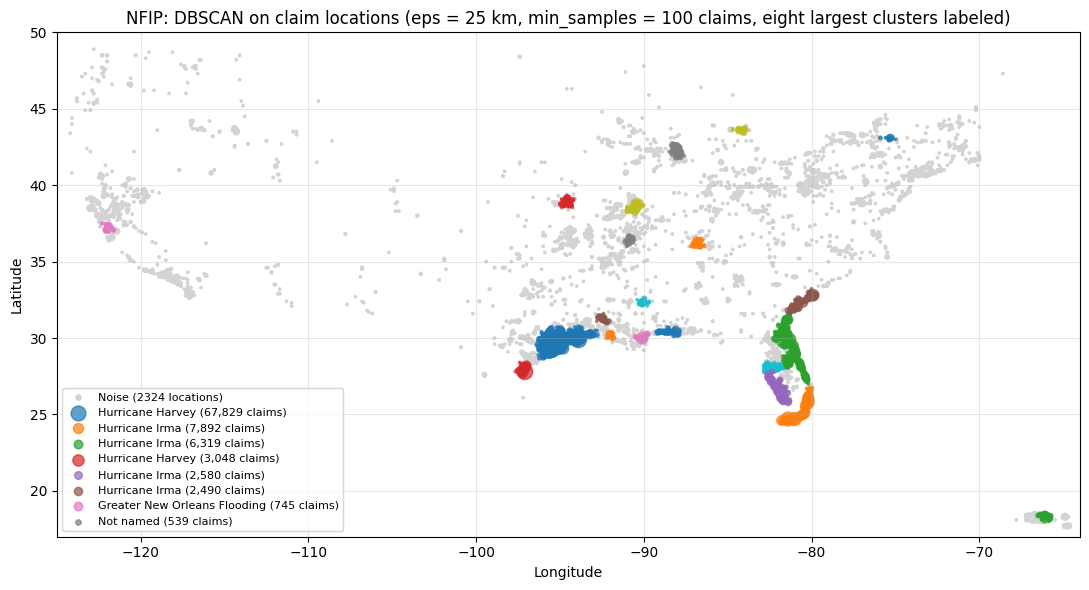

In [5]:
eps_km, ms = 25, 100
lab = results[(eps_km, ms)]
data['dbscan'] = lab[claim_cell]
db_profile = (data[data['dbscan'] >= 0].groupby('dbscan')
              .agg(claims=('largeClaim', 'size'), latitude=('latitude', 'mean'), longitude=('longitude', 'mean'),
                   mainEvent=('event', lambda s: s.value_counts().index[0]),
                   mainEventShare=('event', lambda s: s.value_counts(normalize=True).iloc[0]),
                   largeClaimShare=('largeClaim', 'mean'), medianDepth=('waterDepth', 'median'))
              .sort_values('claims', ascending=False))
print(f'DBSCAN with eps = {eps_km} km and min_samples = {ms} claims: {lab.max() + 1} clusters')
print(db_profile.head(10).round(3).to_string())
noise = data[data['dbscan'] == -1]
print(f'\nNoise claims: {len(noise)} | large-claim share {noise["largeClaim"].mean():.3f} against '
      f'{data.loc[data["dbscan"] >= 0, "largeClaim"].mean():.3f} in clusters')
print('Most common flood events among noise claims:')
print(noise['event'].value_counts().head(4).to_string())

# Compare with k-means on the same locations, with k set to the number of DBSCAN clusters holding 1,000 or more claims
k = int((db_profile['claims'] >= 1000).sum())
km_xy = np.c_[cells['longitude'] * 111.32 * np.cos(np.radians(cells['latitude'])), cells['latitude'] * 110.57]
km_lab = KMeans(n_clusters=k, n_init=10, random_state=0).fit(km_xy, sample_weight=cells['claims']).labels_[claim_cell]
print(f'\nk-means with k = {k}: ARI with flood event {adjusted_rand_score(data["event"], km_lab):.3f} | '
      f'DBSCAN: {adjusted_rand_score(data["event"], data["dbscan"]):.3f}')

fig, ax = plt.subplots(figsize=(11, 6))
is_noise = lab == -1
ax.scatter(cells.loc[is_noise, 'longitude'], cells.loc[is_noise, 'latitude'], s=np.sqrt(cells.loc[is_noise, 'claims']) * 3,
           color='lightgray', label=f'Noise ({is_noise.sum()} locations)')
top = db_profile.index[:8]
for c in db_profile.index:
    pts = cells[lab == c]
    ax.scatter(pts['longitude'], pts['latitude'], s=np.sqrt(pts['claims']) * 3, alpha=0.7,
               label=f'{db_profile.loc[c, "mainEvent"]} ({db_profile.loc[c, "claims"]:,} claims)' if c in top else None)
ax.set_xlim(-125, -64)
ax.set_ylim(17, 50)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(f'NFIP: DBSCAN on claim locations (eps = {eps_km} km, min_samples = {ms} claims, eight largest clusters labeled)')
ax.legend(fontsize=8, loc='lower left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

DBSCAN finds 22 clusters, and the largest ones are the 2017 disasters. Harvey's Houston area forms one cluster of 67,829 claims (98.8% Harvey), with a separate Harvey cluster of 3,048 claims around Corpus Christi and Rockport near the landfall point. Irma splits into southern Florida and the Keys (7,892 claims), northeastern Florida (6,319), southwestern Florida (2,580), and coastal South Carolina and Georgia (2,490). Smaller clusters pick out the Greater New Orleans flooding (745), the late spring storms near St. Louis (486), and an unnamed flood near Chicago (539).

The 6,372 noise claims are the scattered ones. 71% of them have no event name, and only 16% paid more than $50,000, against 55.7% in the clusters. DBSCAN separates the large regional disasters from everyday flooding, and the two have very different payouts. K-means with the same number of large clusters (6) agrees slightly more with the event names (ARI 0.872 against 0.820), since it assigns every claim to an event area, while DBSCAN sets the scattered claims aside, which is the point of using it.

## Part B - Hierarchical clustering of counties

HAC needs the distance between every pair of points, so it does not scale to 100,000 claims, and a dendrogram with that many leaves could not be read. This part clusters counties instead. Each county with at least 50 claims is described by its median water depth, mean log replacement cost, share of elevated buildings, median construction year, shares of claims in A and V zones, and share of primary residences, all standardized. Payouts are left out, so each county's share of large claims can be used afterward. The next cell builds the tree with each linkage method and compares them by the cophenetic correlation (how well the tree's merge heights preserve the original distances between counties), the cluster sizes when the tree is cut into four clusters, and the silhouette.

Claims with a county code: 100702 of 101042
Counties with 50 or more claims: 97
mainEvent
Hurricane Irma                  32
Not named                       31
Hurricane Harvey                22
Late spring severe storms        9
Greater New Orleans Flooding     2

 Linkage  Cophenetic correlation Cluster sizes at 4 clusters  Silhouette at 4 clusters  Clusters with one county
  single                   0.841               [94, 1, 1, 1]                     0.230                         3
complete                   0.638              [83, 12, 1, 1]                     0.245                         2
 average                   0.854               [88, 7, 1, 1]                     0.313                         2
    ward                   0.541              [57, 31, 8, 1]                     0.168                         1


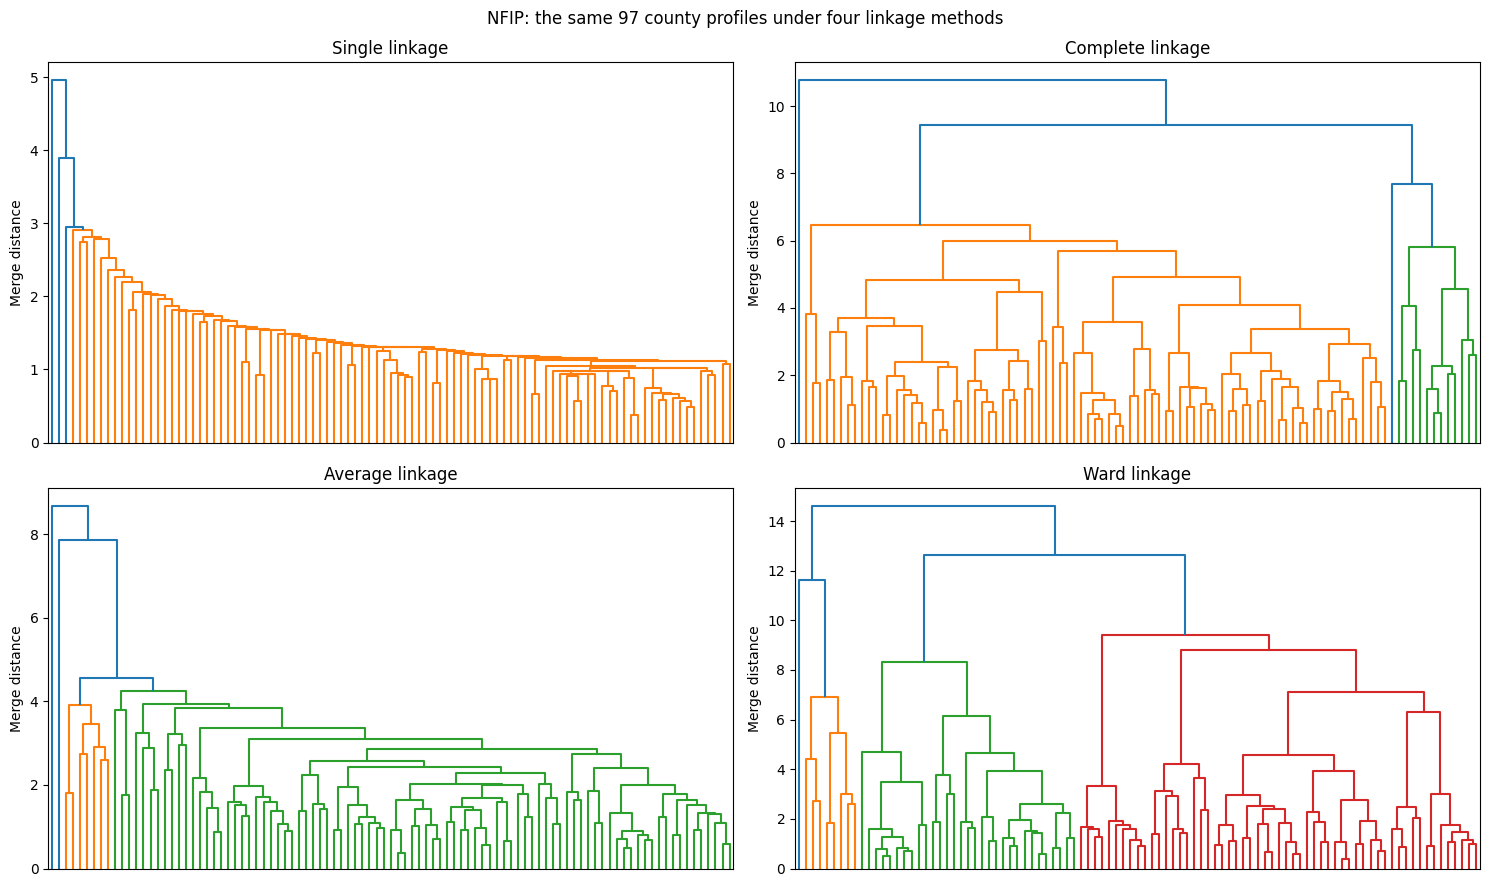

In [6]:
with_county = data.dropna(subset=['countyCode']).copy()
with_county['county'] = with_county['state'] + '-' + with_county['countyCode'].astype(int).astype(str)
print('Claims with a county code:', len(with_county), 'of', len(data))
counties = with_county.groupby('county').agg(claims=('largeClaim', 'size'), waterDepth=('waterDepth', 'median'),
                                      logReplacementCost=('logReplacementCost', 'mean'),
                                      elevated=('elevatedBuildingIndicator', 'mean'),
                                      constructionYear=('constructionYear', 'median'), zoneA=('zoneA', 'mean'),
                                      zoneV=('zoneV', 'mean'), primary=('primaryResidenceIndicator', 'mean'),
                                      largeClaimShare=('largeClaim', 'mean'),
                                      mainEvent=('event', lambda s: s.value_counts().index[0]))
counties = counties[counties['claims'] >= 50]
county_features = ['waterDepth', 'logReplacementCost', 'elevated', 'constructionYear', 'zoneA', 'zoneV', 'primary']
Zc = StandardScaler().fit_transform(counties[county_features])
print('Counties with 50 or more claims:', len(counties))
print(counties['mainEvent'].value_counts().head(5).to_string())

link_rows, links = [], {}
for method in ['single', 'complete', 'average', 'ward']:
    L = linkage(Zc, method=method)
    links[method] = L
    coph, _ = cophenet(L, pdist(Zc))
    lab4 = fcluster(L, 4, criterion='maxclust')
    sizes = sorted(np.bincount(lab4)[1:].tolist(), reverse=True)
    link_rows.append({'Linkage': method, 'Cophenetic correlation': coph, 'Cluster sizes at 4 clusters': sizes,
                      'Silhouette at 4 clusters': silhouette_score(Zc, lab4),
                      'Clusters with one county': sum(s == 1 for s in sizes)})
print()
print(pd.DataFrame(link_rows).round(3).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, method in zip(axes.ravel(), ['single', 'complete', 'average', 'ward']):
    dendrogram(links[method], ax=ax, no_labels=True, color_threshold=links[method][-3, 2])
    ax.set_title(f'{method.capitalize()} linkage')
    ax.set_ylabel('Merge distance')
fig.suptitle(f'NFIP: the same {len(counties)} county profiles under four linkage methods')
plt.tight_layout()
plt.show()

The linkage method changes the tree completely. Single linkage merges the two clusters whose closest members are nearest, so it builds long chains, and cut into four clusters it leaves one cluster of 94 counties and three single counties. Average linkage does much the same (88, 7, 1, and 1), and complete linkage leaves two single counties. Ward linkage merges the pair that adds the least within-cluster variance, which favors compact clusters of similar size, and it gives the most balanced split (57, 31, 8, and 1).

The scores point the other way. Average linkage has the highest cophenetic correlation (0.854) and silhouette (0.313), and Ward has the lowest of both (0.541 and 0.168). Both scores reward a tree that sets a few outlying counties apart from everyone else, because those outliers are far from all other counties. A cut that isolates three outliers is faithful to the distances but says nothing about the other 94 counties, so I used Ward for interpretation and accepted its lower scores. The dendrograms show the difference, with single linkage climbing in a long staircase of one county at a time and Ward splitting into a few large branches.

### The Ward clusters

Largest jumps in Ward merge distance, from the top of the tree: [1.98 1.   2.2  0.58 0.49 1.22 0.19 0.62]
             counties  claims  waterDepth  elevated  constructionYear  zoneA  zoneV  primary  largeClaimShare                  mainEvent
wardCluster                                                                                                                             
1                   8    7761         2.5      0.46            1977.0   0.83   0.01     0.37             0.39  Late spring severe storms
2                   1     125         1.0      0.62            1988.0   0.45   0.42     0.45             0.16                  Not named
3                  31   69064         1.0      0.13            1977.0   0.50   0.01     0.71             0.38                  Not named
4                  57   18084         1.0      0.29            1976.0   0.73   0.02     0.71             0.24             Hurricane Irma
Cluster 1 largest counties: FL-12087, TX-48355, MO-29099, MO-29071, AR-5

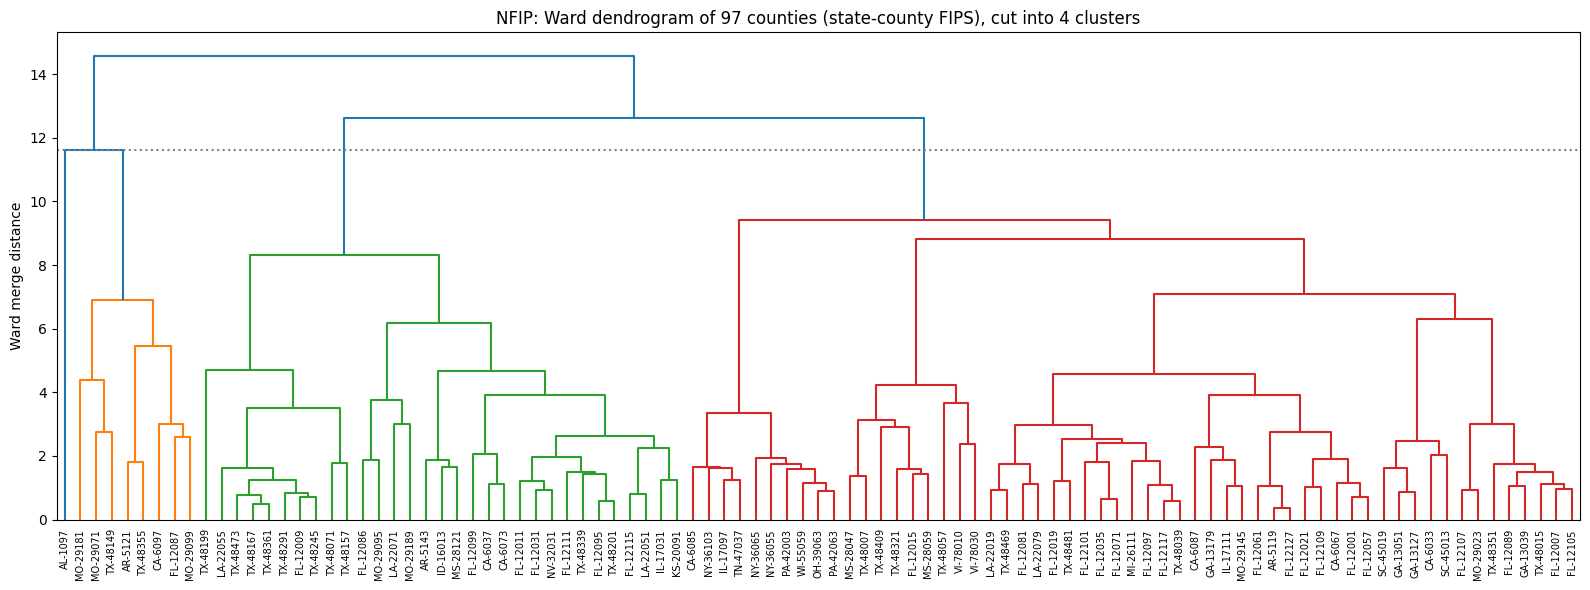

In [7]:
L = links['ward']
gaps = np.diff(L[:, 2])[::-1][:8]
print('Largest jumps in Ward merge distance, from the top of the tree:', np.round(gaps, 2))
n_clusters = 4
counties['wardCluster'] = fcluster(L, n_clusters, criterion='maxclust')
summary = counties.groupby('wardCluster').agg(counties=('claims', 'size'), claims=('claims', 'sum'),
                                              waterDepth=('waterDepth', 'median'), elevated=('elevated', 'mean'),
                                              constructionYear=('constructionYear', 'median'), zoneA=('zoneA', 'mean'),
                                              zoneV=('zoneV', 'mean'), primary=('primary', 'mean'),
                                              largeClaimShare=('largeClaimShare', 'mean'),
                                              mainEvent=('mainEvent', lambda s: s.value_counts().index[0]))
print(summary.round(2).to_string())
for c in summary.index:
    names = counties[counties['wardCluster'] == c].sort_values('claims', ascending=False).index[:6].tolist()
    print(f'Cluster {c} largest counties: {", ".join(names)}')

# Stability, drop 10% of counties at random and refit
ari = []
rng = np.random.RandomState(0)
for _ in range(20):
    keep = rng.rand(len(Zc)) > 0.1
    sub = fcluster(linkage(Zc[keep], 'ward'), n_clusters, criterion='maxclust')
    ari.append(adjusted_rand_score(counties['wardCluster'].values[keep], sub))
print(f'\nWard clusters after dropping 10% of counties (20 repeats): ARI median {np.median(ari):.3f}, min {min(ari):.3f}')

fig, ax = plt.subplots(figsize=(16, 6))
dendrogram(L, labels=counties.index.tolist(), leaf_font_size=7, color_threshold=L[-(n_clusters - 1), 2], ax=ax)
ax.axhline(L[-(n_clusters - 1), 2], color='gray', linestyle=':')
ax.set_ylabel('Ward merge distance')
ax.set_title(f'NFIP: Ward dendrogram of {len(counties)} counties (state-county FIPS), cut into {n_clusters} clusters')
plt.tight_layout()
plt.show()

The largest gaps between successive Ward merges come near the top of the tree, 1.98 between the last two merges and 2.20 between the third and fourth from the top, so the tree supports a cut into two or four clusters. Four clusters are more informative.

- **Cluster 3** (31 counties, 69,064 claims) is the Harvey counties around Houston, including Harris, Galveston, Jefferson, Orange, Fort Bend, and Montgomery. Few buildings are elevated (13%) and only half the claims are in A zones, so much of the flooding reached buildings outside the mapped high-risk zone.
- **Cluster 4** (57 counties, 18,084 claims) is mostly the Irma counties in Florida and South Carolina, with more A-zone claims (73%) and more elevated buildings (29%). Its counties average 24% large claims, against 38% for the Harvey cluster.
- **Cluster 1** (8 counties) has the deepest water (median 2.5) and few primary residences (37%). It mixes inland river flooding in Missouri and Arkansas with the Florida Keys and the Texas coast near Corpus Christi.
- **Cluster 2** is a single county, Mobile County in Alabama (AL-1097), with many V-zone claims (42%).

Dropping 10% of the counties at random and refitting gives a median ARI of 0.649 with the full clusters, but as low as 0.264 in one repeat, so the Ward clusters are only moderately stable. The county profiles do not fall into sharply separate groups, and which branch a county joins can change when a few others are removed.

## Discussion

### Overfitting

Clustering has no test set, so overfitting shows up as structure that would not reappear in other data. For DBSCAN the guard was to judge settings across a whole grid instead of tuning to one number, and to check the result against outside information. The clusters match FEMA's event names (ARI 0.820), and the main disaster clusters appear at every setting in the grid. Setting `min_samples` high (100 claims) also keeps DBSCAN from declaring a cluster out of a few nearby claims. For HAC the risk was reading meaning into a tree built from only 97 counties. The comparison of linkages showed that single and average linkage mostly isolate outliers, and the resampling check showed the Ward clusters are only moderately stable (median ARI 0.649), so the county clusters are treated as a rough grouping, not as fixed types.

### Metrics and hyperparameter tuning

DBSCAN has two hyperparameters. `eps` (25 km) is the radius that defines a neighborhood, and `min_samples` (100 claims) is how many claims a neighborhood needs for its center to count as dense. Together they set the minimum density of a flood cluster, 100 claims within 25 km. They were chosen with the k-distance plot and a grid compared by the ARI with FEMA's event names, the noise share, and the number of clusters. HAC's choices are the linkage method and where to cut the tree. They were compared by the cophenetic correlation (0.541 to 0.854), the silhouette, and the cluster sizes, and the cut was placed at the largest gaps in Ward merge distance. The metrics disagreed, since the highest cophenetic correlation and silhouette came from trees that only set outliers apart, so the cluster sizes and the dendrograms were part of the decision.

### Expected or unexpected

I expected DBSCAN to find the hurricanes, but not to split Harvey into Houston and the Corpus Christi landfall area, or Irma into four coastal pieces. The most interesting result was the noise. The 6.3% of claims that DBSCAN set aside are mostly unnamed, everyday floods with far smaller payouts (16% large claims against 56%), which k-means had no way to show. On the HAC side, I expected the linkage method to matter, but not that the two standard scores would both favor the least useful trees. The Harvey county cluster's low share of A-zone claims (50%) was also unexpected, and it shows how far Harvey's flooding reached beyond the mapped high-risk zones.

### How EDA helped

Earlier EDA set up both methods. The coordinate rounding found in Week 8 is why DBSCAN runs on 3,580 weighted locations, which made it fast and set a natural lower bound for `eps` at the 11 km grid spacing. The Week 10 finding that 100 locations hold 72% of claims predicted that a density method would find a few very large clusters and much sparse noise. For the counties, the skew in water depth and replacement cost found in Module B is why the profiles use the median depth and the mean of the log cost. EDA did not show that the scattered claims pay so much less, which only appeared once DBSCAN separated them.

### External sources

- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining (KDD-96)*, 226-231.
- Schubert, E., Sander, J., Ester, M., Kriegel, H.-P., & Xu, X. (2017). DBSCAN revisited, revisited. Why and how you should (still) use DBSCAN. *ACM Transactions on Database Systems*, 42(3), 1-21.
- scikit-learn User Guide, "Clustering," the sections on DBSCAN and hierarchical clustering: https://scikit-learn.org/stable/modules/clustering.html
- SciPy documentation, `scipy.cluster.hierarchy.linkage`, which defines the single, complete, average, and Ward linkage methods: https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html

### Conclusions

DBSCAN on claim locations separates the 2017 flood disasters from everyday flooding without being told the number of clusters. Its 22 clusters match FEMA's event names (ARI 0.820), and its noise, 6.3% of claims, is a distinct group with far smaller payouts (16% over $50,000 against 56% in the clusters). Hierarchical clustering of 97 counties showed how much the linkage method matters. Single and average linkage chain outliers together and leave one giant cluster, while Ward linkage gives balanced, readable groups, with the Harvey counties standing out for their low shares of elevated and A-zone buildings, though those groups are only moderately stable.

For Milestone Two and the Capstone, DBSCAN gives a useful new feature, whether a claim belongs to a major disaster cluster or is an isolated flood, which separates payouts about as sharply as any building feature. The county results also suggest that flood-zone maps understated Harvey's risk, which is worth testing directly with the elevation and zone data in the Capstone.